In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

print("torch version:", torch.__version__)

torch version: 2.15.0+cpu


In [2]:
!wget "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv" -O Folds5x2_pp.csv
!ls

--2026-10-30 13:33:26--  https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 318263 (311K) [text/plain]
Saving to: ‘Folds5x2_pp.csv’

Folds5x2_pp.csv     100%[===================>] 310.80K  --.-KB/s    in 0.09s   

2026-10-30 13:33:27 (3.42 MB/s) - ‘Folds5x2_pp.csv’ saved [318263/318263]

CPE486586_HigginbothamArwen_HW_04.ipynb	 Folds5x2_pp.csv  venv


In [3]:
df = pd.read_csv("Folds5x2_pp.csv")
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
df.shape

(9568, 5)

In [5]:
df.isna().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
df.describe()

,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [7]:
features = ["AT", "V", "AP", "RH"]   # x1, x2, x3, x4
target = "PE"                        # y

X = df[features].values              # shape (9568, 4)
y = df[target].values                # shape (9568,)

print(X.shape, y.shape)

(9568, 4) (9568,)


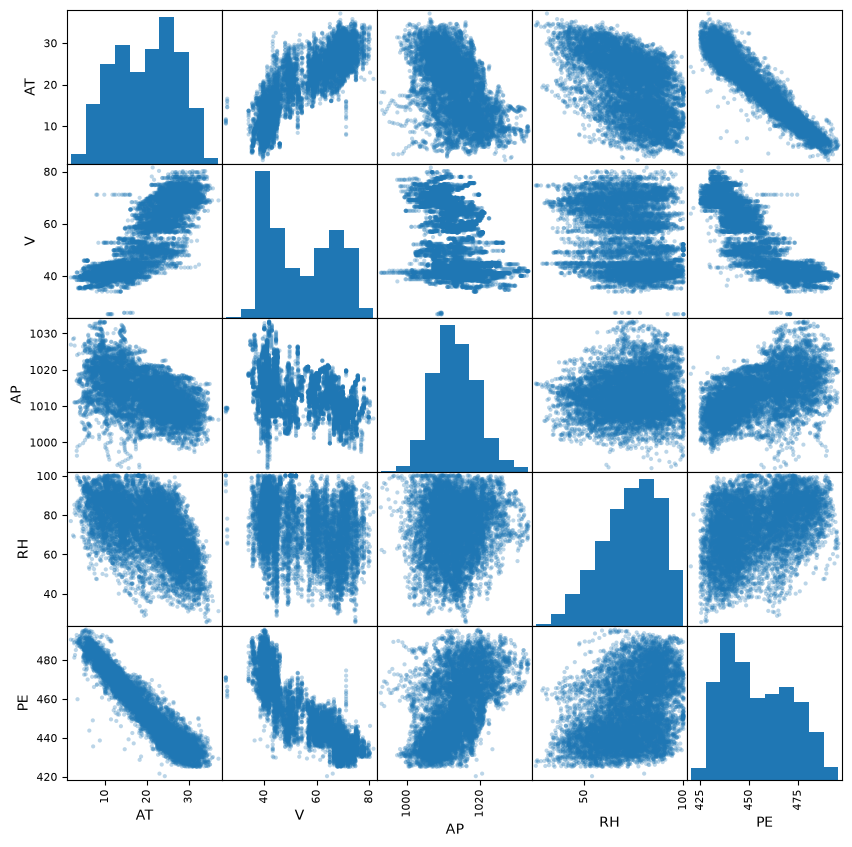

In [8]:
from pandas.plotting import scatter_matrix

scatter_matrix(df[features + [target]], figsize=(10, 10), diagonal="hist", alpha=0.3)
plt.show()

In [9]:
df[features + [target]].corr().round(2)

,AT,V,AP,RH,PE
AT,1.00,0.84,-0.51,-0.54,-0.95
V,0.84,1.00,-0.41,-0.31,-0.87
AP,-0.51,-0.41,1.00,0.10,0.52
RH,-0.54,-0.31,0.10,1.00,0.39
PE,-0.95,-0.87,0.52,0.39,1.00


In [10]:
import numpy as np

y = 3.0
y_hat = 2.0
loss = 0.5 * np.log(1 + (y - y_hat) ** 2)
print(loss)   # about 0.3466

0.34657359027997264


In [11]:
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
Xs = (X - X_mean) / X_std

print(Xs.mean(axis=0).round(3))   # should be about 0
print(Xs.std(axis=0).round(3))    # should be about 1

[-0. -0.  0. -0.]
[1. 1. 1. 1.]


In [12]:
features = ["AT", "V", "AP", "RH"]
target = "PE"
X = df[features].values
y = df[target].values
print(X.shape, y.shape)

(9568, 4) (9568,)


In [13]:
Xt = torch.tensor(Xs, dtype=torch.float64)
yt = torch.tensor(y, dtype=torch.float64)
print(Xt.shape, yt.shape, Xt.dtype)

torch.Size([9568, 4]) torch.Size([9568]) torch.float64


In [14]:
def cauchy_loss(y_hat, y, c=1.0):
    r = (y - y_hat) / c
    return (c**2 / 2 * torch.log1p(r**2)).mean()

In [15]:
y_true = torch.tensor([0.0, 0.0, 0.0], dtype=torch.float64)
for err in [0.0, 1.0, 100.0]:
    y_pred = torch.tensor([err, err, err], dtype=torch.float64)
    print(f"error {err:6.1f}  cauchy {cauchy_loss(y_pred, y_true).item():.4f}  half-squared {0.5*err**2:.1f}")

error    0.0  cauchy 0.0000  half-squared 0.0
error    1.0  cauchy 0.3466  half-squared 0.5
error  100.0  cauchy 4.6052  half-squared 5000.0


In [16]:
w = torch.zeros(4, dtype=torch.float64, requires_grad=True)
b = yt.mean().clone().detach().requires_grad_(True)

optimizer = torch.optim.Adam([w, b], lr=0.05)

losses = []
for epoch in range(3000):
    optimizer.zero_grad()
    y_hat = Xt @ w + b
    loss = cauchy_loss(y_hat, yt)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 500 == 0:
        print(epoch, loss.item())

print("final loss:", losses[-1])

0 2.4692069646442163
500 1.1485812518055547
1000 1.1347841214650036
1500 1.1347737267441784
2000 1.134773726724315
2500 1.134773726724315
final loss: 1.134773726724315


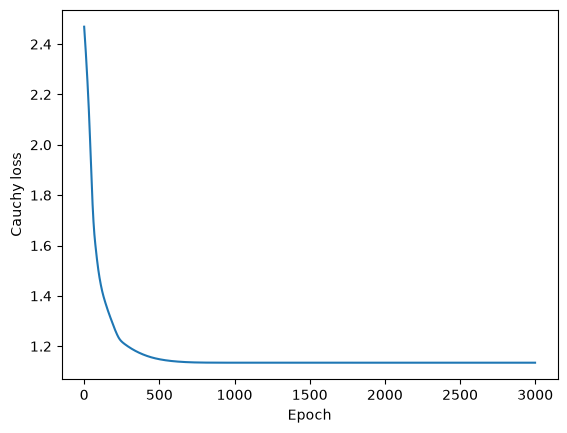

In [17]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Cauchy loss")
plt.show()

In [18]:
w_std = w.detach().numpy()
b_std = b.detach().item()

w_orig = w_std / X_std
w0_orig = b_std - np.sum(w_std * X_mean / X_std)

coef = np.concatenate([[w0_orig], w_orig])

names = ["w0 (intercept)", "w1 (AT)", "w2 (V)", "w3 (AP)", "w4 (RH)"]
for n, v in zip(names, coef):
    print(f"{n:16s} {v: .6f}")

w0 (intercept)    511.559333
w1 (AT)          -2.082566
w2 (V)           -0.235827
w3 (AP)           0.007403
w4 (RH)          -0.154875


In [19]:
y_hat_orig = coef[0] + X @ coef[1:]
loss_orig = cauchy_loss(torch.tensor(y_hat_orig), torch.tensor(y)).item()
print("loss with original-unit coefficients:", loss_orig)
print("final training loss:                 ", losses[-1])

loss with original-unit coefficients: 1.134773726724315
final training loss:                  1.134773726724315


In [20]:
A = np.column_stack([np.ones(len(X)), X])
ols_coef, *_ = np.linalg.lstsq(A, y, rcond=None)

pd.DataFrame({"Cauchy": coef, "OLS": ols_coef}, index=names).round(5)

,Cauchy,OLS
w0 (intercept),511.55933,454.60927
w1 (AT),-2.08257,-1.97751
w2 (V),-0.23583,-0.23392
w3 (AP),0.00740,0.06208
w4 (RH),-0.15487,-0.15805


In [21]:
class CauchyRegression:
    """Multiple linear regression fit with the Cauchy loss, using PyTorch."""

    def __init__(self, c=1.0, lr=0.05, epochs=3000, verbose=True):
        self.c = c
        self.lr = lr
        self.epochs = epochs
        self.verbose = verbose
        self.loss_history = []
        self.coef_ = None          # [w0, w1, ..., wp] in ORIGINAL units
        self.final_loss_ = None

    def _loss(self, y_hat, y):
        r = (y - y_hat) / self.c
        return (self.c ** 2 / 2 * torch.log1p(r ** 2)).mean()

    def fit(self, X, y):
        X = torch.tensor(np.asarray(X, dtype=np.float64))
        y = torch.tensor(np.asarray(y, dtype=np.float64))

        # standardize features
        mu = X.mean(dim=0)
        sigma = X.std(dim=0, correction=0)
        Xs = (X - mu) / sigma

        # parameters
        w = torch.zeros(X.shape[1], dtype=X.dtype, requires_grad=True)
        b = y.mean().clone().detach().requires_grad_(True)
        opt = torch.optim.Adam([w, b], lr=self.lr)

        self.loss_history = []
        for epoch in range(self.epochs):
            opt.zero_grad()
            loss = self._loss(Xs @ w + b, y)
            loss.backward()
            opt.step()
            self.loss_history.append(loss.item())
            if self.verbose and epoch % 500 == 0:
                print(f"epoch {epoch:5d}  loss {loss.item():.6f}")

        # convert back to original units
        w_orig = w.detach() / sigma
        w0 = b.detach() - (w.detach() * mu / sigma).sum()
        self.coef_ = torch.cat([w0.reshape(1), w_orig]).numpy()
        self.final_loss_ = self.loss_history[-1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return self.coef_[0] + X @ self.coef_[1:]

    def confidence_intervals(self, X, y, z=1.96):
        """Approximate 95% Wald intervals from the inverse Hessian of the Cauchy NLL."""
        X = torch.tensor(np.asarray(X, dtype=np.float64))
        y = torch.tensor(np.asarray(y, dtype=np.float64))
        X1 = torch.cat([torch.ones(len(X), 1, dtype=X.dtype), X], dim=1)

        def nll(theta):
            r = (y - X1 @ theta) / self.c
            return torch.log1p(r ** 2).sum()

        theta = torch.tensor(self.coef_)
        H = torch.autograd.functional.hessian(nll, theta)
        cov = torch.linalg.inv(H)
        se = torch.sqrt(torch.diag(cov)).numpy()
        ci = np.column_stack([self.coef_ - z * se, self.coef_ + z * se])
        return ci, se

In [22]:
model = CauchyRegression(c=1.0, lr=0.05, epochs=3000)
model.fit(X, y)

print("coefficients:", model.coef_)
print("final loss:  ", model.final_loss_)

epoch     0  loss 2.469207
epoch   500  loss 1.148581
epoch  1000  loss 1.134784
epoch  1500  loss 1.134774
epoch  2000  loss 1.134774
epoch  2500  loss 1.134774
coefficients: [ 5.11559333e+02 -2.08256577e+00 -2.35827320e-01  7.40259674e-03
 -1.54874525e-01]
final loss:   1.134773726724315


In [23]:
model = CauchyRegression(c=1.0, lr=0.05, epochs=3000, verbose=False)
model.fit(X, y)

ci, se = model.confidence_intervals(X, y)

names = ["w0 (intercept)", "w1 (AT)", "w2 (V)", "w3 (AP)", "w4 (RH)"]
table = pd.DataFrame({"coef": model.coef_, "std err": se,
                      "2.5%": ci[:, 0], "97.5%": ci[:, 1]}, index=names)
table.round(5)

,coef,std err,2.5%,97.5%
w0 (intercept),511.55933,8.42772,495.04100,528.07767
w1 (AT),-2.08257,0.01292,-2.10789,-2.05725
w2 (V),-0.23583,0.00594,-0.24748,-0.22418
w3 (AP),0.00740,0.00820,-0.00866,0.02347
w4 (RH),-0.15487,0.00351,-0.16175,-0.14800


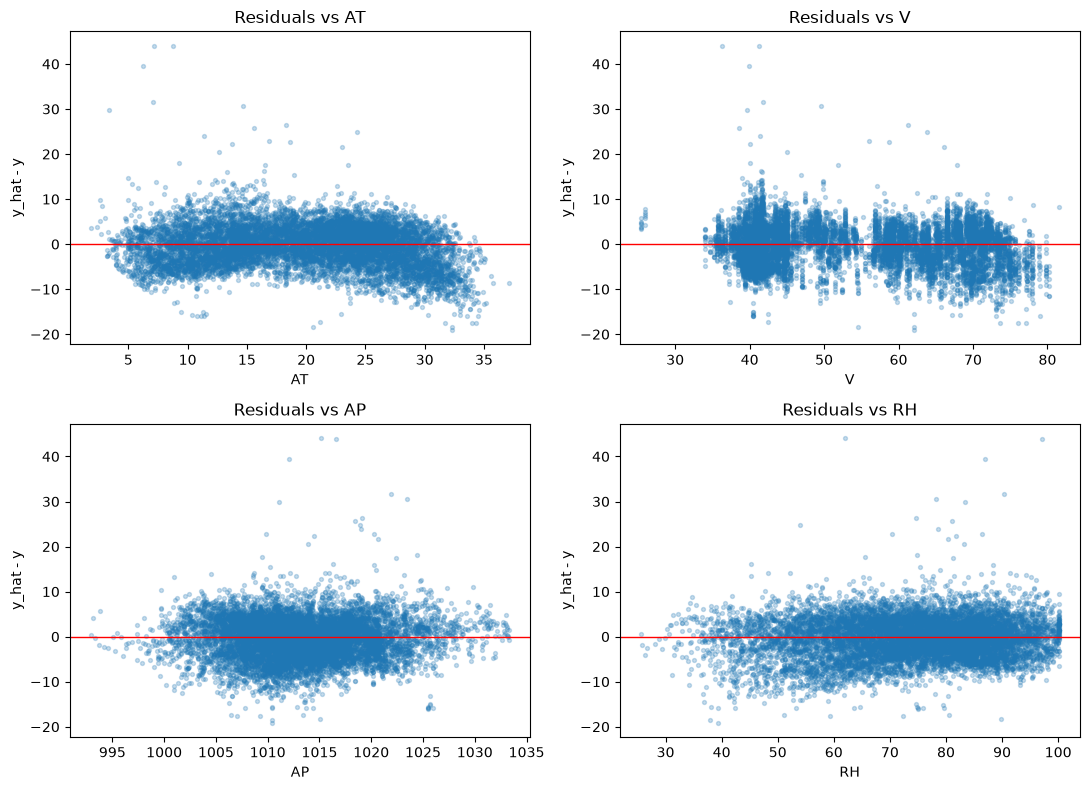

In [24]:
y_hat = model.predict(X)
resid = y_hat - y

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, f in zip(axes.ravel(), features):
    ax.scatter(df[f], resid, alpha=0.25, s=8)
    ax.axhline(0, color="red", linewidth=1)
    ax.set_xlabel(f)
    ax.set_ylabel("y_hat - y")
    ax.set_title(f"Residuals vs {f}")
plt.tight_layout()
plt.show()

In [25]:
print("mean residual:  ", resid.mean().round(3))
print("median residual:", np.median(resid).round(3))
print("std residual:   ", resid.std().round(3))
print("min / max:      ", resid.min().round(2), "/", resid.max().round(2))

mean residual:   -0.39
median residual: -0.216
std residual:    4.614
min / max:       -19.11 / 44.08


In [26]:
!find ~ -name regression.py -not -path "*/venv/*" -not -path "*/site-packages/*" 2>/dev/null

/home/arwen/.cache/uv/archive-v0/T-z0r475tPl6rshi/seaborn/_stats/regression.py
/home/arwen/.cache/uv/archive-v0/T-z0r475tPl6rshi/seaborn/regression.py
/home/arwen/.cache/uv/archive-v0/4Ihv968ldSsCRcoc/sklearn/metrics/_plot/regression.py
/home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model/regression.py


In [27]:
!ls /home/arwen/zeusandatlas/hydro_regression
!ls /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression
!ls /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model

README.md  pyproject.toml  src	uv.lock
__init__.py  __pycache__  model	 py.typed
__init__.py  __pycache__  regression.py	 regression.py.bak


In [28]:
!head -40 /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model/regression.py

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


def _to_tensor(a):
    """Convert list / numpy / pandas to a 1D float32 tensor."""
    return torch.tensor(np.asarray(a, dtype=np.float32)).flatten()


class LinearRegression(nn.Module):
    # (a) constructor
    def __init__(self, learning_rate=0.01, epochs=100):
        super().__init__()
        self.learning_rate = learning_rate
        self.epochs = epochs

        # nn.Parameter -> tracked by autograd and returned by .parameters()
        self.w0 = nn.Parameter(torch.zeros(1))
        self.w1 = nn.Parameter(torch.zeros(1))

        self.optimizer = torch.optim.SGD(self.parameters(), lr=learning_rate)
        self.loss_fn = nn.MSELoss()

        # storage for intermediate values during training
        self.history = {"w0": [], "w1": [], "loss": []}

    # (b) linear model
    def forward(self, x):
        return self.w0 + self.w1 * x

    # (c) training + R^2 on test data
    def fit(self, X_t

In [29]:
!cp /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model/regression.py /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model/regression.py.bak

In [30]:
%%writefile -a /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model/regression.py


class CauchyRegression:
    """Multiple linear regression fit with the Cauchy loss, using PyTorch."""

    def __init__(self, c=1.0, lr=0.05, epochs=3000, verbose=True):
        self.c = c
        self.lr = lr
        self.epochs = epochs
        self.verbose = verbose
        self.loss_history = []
        self.coef_ = None          # [w0, w1, ..., wp] in ORIGINAL units
        self.final_loss_ = None

    def _loss(self, y_hat, y):
        r = (y - y_hat) / self.c
        return (self.c ** 2 / 2 * torch.log1p(r ** 2)).mean()

    def fit(self, X, y):
        X = torch.tensor(np.asarray(X, dtype=np.float64))
        y = torch.tensor(np.asarray(y, dtype=np.float64))

        # standardize features
        mu = X.mean(dim=0)
        sigma = X.std(dim=0, correction=0)
        Xs = (X - mu) / sigma

        # parameters
        w = torch.zeros(X.shape[1], dtype=X.dtype, requires_grad=True)
        b = y.mean().clone().detach().requires_grad_(True)
        opt = torch.optim.Adam([w, b], lr=self.lr)

        self.loss_history = []
        for epoch in range(self.epochs):
            opt.zero_grad()
            loss = self._loss(Xs @ w + b, y)
            loss.backward()
            opt.step()
            self.loss_history.append(loss.item())
            if self.verbose and epoch % 500 == 0:
                print(f"epoch {epoch:5d}  loss {loss.item():.6f}")

        # convert back to original units
        w_orig = w.detach() / sigma
        w0 = b.detach() - (w.detach() * mu / sigma).sum()
        self.coef_ = torch.cat([w0.reshape(1), w_orig]).numpy()
        self.final_loss_ = self.loss_history[-1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return self.coef_[0] + X @ self.coef_[1:]

    def confidence_intervals(self, X, y, z=1.96):
        """Approximate 95% Wald intervals from the inverse Hessian of the Cauchy NLL."""
        X = torch.tensor(np.asarray(X, dtype=np.float64))
        y = torch.tensor(np.asarray(y, dtype=np.float64))
        X1 = torch.cat([torch.ones(len(X), 1, dtype=X.dtype), X], dim=1)

        def nll(theta):
            r = (y - X1 @ theta) / self.c
            return torch.log1p(r ** 2).sum()

        theta = torch.tensor(self.coef_)
        H = torch.autograd.functional.hessian(nll, theta)
        cov = torch.linalg.inv(H)
        se = torch.sqrt(torch.diag(cov)).numpy()
        ci = np.column_stack([self.coef_ - z * se, self.coef_ + z * se])
        return ci, se

Appending to /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model/regression.py


In [31]:
!grep -n "^class \|^def \|^import " /home/arwen/zeusandatlas/hydro_regression/src/hydro_regression/model/regression.py

1:import numpy as np
2:import torch
3:import torch.nn as nn
4:import matplotlib.pyplot as plt
7:def _to_tensor(a):
12:class LinearRegression(nn.Module):
93:class CauchyRegression:
162:class CauchyRegression:


In [32]:
!pip install -e /home/arwen/zeusandatlas/hydro_regression --no-deps

Obtaining file:///home/arwen/zeusandatlas/hydro_regression
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for hydro-regression (pyproject.toml) ... done
  Created wheel for hydro-regression: filename=hydro_regression-0.1.0-py3-none-any.whl size=1503 sha256=286db2e405ce357772aaceba2f5409c2b5f90630dd243a1937dbc98e70f23209
  Stored in directory: /tmp/pip-ephem-wheel-cache-udgigjiu/wheels/6b/bb/b3/40acc809f7678491e534dffd31f2adcbf16aeebec92f51a3bd
Successfully built hydro-regression
  Attempting uninstall: hydro-regression
    Found existing installation: hydro-regression 0.1.0
    Uninstalling hydro-regression-0.1.0:
      Successfully uninstalled hydro-regression-0.1.0


In [33]:
from hydro_regression.model.regression import CauchyRegression
print(CauchyRegression.__module__)

hydro_regression.model.regression


In [34]:
import sys
sys.path.insert(0, "/home/arwen/zeusandatlas/hydro_regression/src")

from hydro_regression.model.regression import CauchyRegression
print(CauchyRegression.__module__)

hydro_regression.model.regression


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2
from hydro_regression.model.regression import CauchyRegression

df = pd.read_csv("Folds5x2_pp.csv")
features = ["AT", "V", "AP", "RH"]
target = "PE"
X = df[features].values
y = df[target].values

model = CauchyRegression(c=1.0, lr=0.05, epochs=3000, verbose=False)
model.fit(X, y)

print(CauchyRegression.__module__)
print(model.coef_)
print(model.final_loss_)

hydro_regression.model.regression
[ 5.11559333e+02 -2.08256577e+00 -2.35827320e-01  7.40259674e-03
 -1.54874525e-01]
1.134773726724315


In [36]:
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel


class CauchyModel(GenericLikelihoodModel):
    def __init__(self, endog, exog, **kwds):
        super().__init__(endog, exog, **kwds)

    def nloglikeobs(self, params):
        resid = self.endog - self.exog @ params
        return -stats.cauchy.logpdf(resid, loc=0, scale=1)

    def fit(self, start_params=None, maxiter=5000, **kwds):
        if start_params is None:
            start_params = np.asarray(sm.OLS(self.endog, self.exog).fit().params)
        return super().fit(start_params=start_params, maxiter=maxiter, **kwds)

In [37]:
Xc = sm.add_constant(df[features])        # adds the intercept column "const"
res = CauchyModel(df[target], Xc).fit(method="bfgs")
print(res.summary())

Optimization terminated successfully.
         Current function value: 3.414277
         Iterations: 30
         Function evaluations: 36
         Gradient evaluations: 36
                             CauchyModel Results                              
Dep. Variable:                     PE   Log-Likelihood:                -32668.
Model:                    CauchyModel   AIC:                         6.535e+04
Method:            Maximum Likelihood   BIC:                         6.538e+04
Date:                Fri, 30 Oct 2026                                         
Time:                        13:33:50                                         
No. Observations:                9568                                         
Df Residuals:                    9563                                         
Df Model:                           4                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

In [38]:
comparison = pd.DataFrame({
    "PyTorch": model.coef_,
    "statsmodels": np.asarray(res.params),
}, index=["w0 (intercept)", "w1 (AT)", "w2 (V)", "w3 (AP)", "w4 (RH)"])
comparison["difference"] = comparison["statsmodels"] - comparison["PyTorch"]
comparison.round(5)

,PyTorch,statsmodels,difference
w0 (intercept),511.55933,511.55882,-0.00051
w1 (AT),-2.08257,-2.08257,0.00000
w2 (V),-0.23583,-0.23583,-0.00000
w3 (AP),0.00740,0.00740,0.00000
w4 (RH),-0.15487,-0.15487,0.00000


In [39]:
ci_torch, se_torch = model.confidence_intervals(X, y)
pd.DataFrame({
    "SE PyTorch": se_torch,
    "SE statsmodels": np.asarray(res.bse),
}, index=comparison.index).round(5)

,SE PyTorch,SE statsmodels
w0 (intercept),8.42772,8.26812
w1 (AT),0.01292,0.01261
w2 (V),0.00594,0.00588
w3 (AP),0.00820,0.00803
w4 (RH),0.00351,0.00349


In [40]:
theta_sm = torch.tensor(np.asarray(res.params), dtype=torch.float64)
Xc_t = torch.tensor(Xc.values.astype(np.float64))
y_t = torch.tensor(np.asarray(y, dtype=np.float64))

def nll(theta):
    return torch.log1p((y_t - Xc_t @ theta) ** 2).sum()

H = torch.autograd.functional.hessian(nll, theta_sm)
se_exact = np.sqrt(np.diag(torch.linalg.inv(H).numpy()))

pd.DataFrame({
    "SE PyTorch": se_torch,
    "SE exact @ sm params": se_exact,
    "SE statsmodels": np.asarray(res.bse),
}, index=comparison.index).round(5)

,SE PyTorch,SE exact @ sm params,SE statsmodels
w0 (intercept),8.42772,8.42774,8.26812
w1 (AT),0.01292,0.01292,0.01261
w2 (V),0.00594,0.00594,0.00588
w3 (AP),0.00820,0.00820,0.00803
w4 (RH),0.00351,0.00351,0.00349


In [50]:
!git -C /home/arwen/zeusandatlas diff --stat

 .../src/hydro_regression/model/regression.py       | 138 +++++++++++++++++++++
 1 file changed, 138 insertions(+)


In [51]:
!ls /home/arwen/zeusandatlas/HWNotebooks

CPE486586-HigginbothamArwen-HW-02


In [52]:
!cp CPE486586_HigginbothamArwen_HW_04.ipynb Folds5x2_pp.csv /home/arwen/zeusandatlas/HWNotebooks/

In [53]:
!ssh -T git@github.com

Hi zeusandatlasgh! You've successfully authenticated, but GitHub does not provide shell access.


In [54]:
!ls -la /home/arwen/zeusandatlas/HWNotebooks
!ls /home/arwen/zeusandatlas/HWNotebooks/CPE486586-HigginbothamArwen-HW-02

total 1752
drwxr-xr-x 2 arwen arwen    4096 Oct 30 14:02 .
drwxr-xr-x 7 arwen arwen    4096 Oct 11 11:30 ..
-rw-r--r-- 1 arwen arwen  377156 Sep 25 14:34 CPE486586-HigginbothamArwen-HW-02
-rw-r--r-- 1 arwen arwen 1082136 Oct 30 14:02 CPE486586_HigginbothamArwen_HW_04.ipynb
-rw-r--r-- 1 arwen arwen  318263 Oct 30 14:02 Folds5x2_pp.csv
/home/arwen/zeusandatlas/HWNotebooks/CPE486586-HigginbothamArwen-HW-02


In [55]:
!git -C /home/arwen/zeusandatlas add HWNotebooks/CPE486586_HigginbothamArwen_HW_04.ipynb HWNotebooks/Folds5x2_pp.csv hydro_regression/src/hydro_regression/model/regression.py
!git -C /home/arwen/zeusandatlas status

On branch hw00
Your branch is up to date with 'origin/hw00'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   HWNotebooks/CPE486586_HigginbothamArwen_HW_04.ipynb
	new file:   HWNotebooks/Folds5x2_pp.csv
	modified:   hydro_regression/src/hydro_regression/model/regression.py

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hydro_regression/src/hydro_regression/__pycache__/__init__.cpython-314.pyc
	hydro_regression/src/hydro_regression/model/__pycache__/__init__.cpython-314.pyc
	hydro_regression/src/hydro_regression/model/__pycache__/regression.cpython-314.pyc
	hydro_regression/src/hydro_regression/model/regression.py.bak



In [56]:
!git -C /home/arwen/zeusandatlas commit -m "Add HW4 notebook and CauchyRegression"
!git -C /home/arwen/zeusandatlas push

[hw00 0dc0698] Add HW4 notebook and CauchyRegression
 3 files changed, 11508 insertions(+)
 create mode 100644 HWNotebooks/CPE486586_HigginbothamArwen_HW_04.ipynb
 create mode 100644 HWNotebooks/Folds5x2_pp.csv
To github.com:zeusandatlasgh/zeusandatlas.git
 ! [rejected]        hw00 -> hw00 (fetch first)
error: failed to push some refs to 'github.com:zeusandatlasgh/zeusandatlas.git'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


In [57]:
!git -C /home/arwen/zeusandatlas fetch
!git -C /home/arwen/zeusandatlas log --oneline HEAD..origin/hw00
!git -C /home/arwen/zeusandatlas diff --stat HEAD...origin/hw00

remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 166.83 KiB | 1.22 MiB/s, done.
From github.com:zeusandatlasgh/zeusandatlas
   2849469..c67f05c  hw00       -> origin/hw00
c67f05c (origin/hw00, origin/HEAD) Add files via upload
 .../CPE486586_HigginbothamArwen_HW_03.ipynb        | 483 +++++++++++++++++++++
 1 file changed, 483 insertions(+)


In [58]:
!git -C /home/arwen/zeusandatlas pull --rebase

Successfully rebased and updated refs/heads/hw00.


In [59]:
!git -C /home/arwen/zeusandatlas push
!git -C /home/arwen/zeusandatlas status

Enumerating objects: 16, done.
Counting objects: 100% (16/16), done.
Delta compression using up to 12 threads
Compressing objects: 100% (9/9), done.
Writing objects: 100% (10/10), 883.09 KiB | 6.35 MiB/s, done.
Total 10 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To github.com:zeusandatlasgh/zeusandatlas.git
   c67f05c..024c77c  hw00 -> hw00
On branch hw00
Your branch is up to date with 'origin/hw00'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hydro_regression/src/hydro_regression/__pycache__/__init__.cpython-314.pyc
	hydro_regression/src/hydro_regression/model/__pycache__/__init__.cpython-314.pyc
	hydro_regression/src/hydro_regression/model/__pycache__/regression.cpython-314.pyc
	hydro_regression/src/hydro_regression/model/regression.py.bak

nothing added to commit but untracked files present (use "git add" to track)


In [60]:
!cp CPE486586_HigginbothamArwen_HW_04.ipynb Folds5x2_pp.csv /home/arwen/zeusandatlas/HWNotebooks/
!git -C /home/arwen/zeusandatlas add HWNotebooks/CPE486586_HigginbothamArwen_HW_04.ipynb
!git -C /home/arwen/zeusandatlas commit -m "Update HW4 notebook"
!git -C /home/arwen/zeusandatlas push

[hw00 2cc0c72] Update HW4 notebook
 1 file changed, 88 insertions(+), 1 deletion(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 12 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.20 KiB | 47.00 KiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To github.com:zeusandatlasgh/zeusandatlas.git
   024c77c..2cc0c72  hw00 -> hw00


In [61]:
# Question 6: Logistic Regression

In [62]:
!pip install ucimlrepo scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 17.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]


In [64]:
from ucimlrepo import fetch_ucirepo

ccd = fetch_ucirepo(id=350)
X_df = ccd.data.features
y_df = ccd.data.targets

print(X_df.shape, y_df.shape)
X_df.head()

(30000, 23) (30000, 1)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [65]:
pd.set_option("display.max_colwidth", None)
ccd.variables

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,NaN,NaN,None,no
1,X1,Feature,Integer,NaN,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,NaN,PAY_0,None,no
7,X7,Feature,Integer,NaN,PAY_2,None,no
8,X8,Feature,Integer,NaN,PAY_3,None,no
9,X9,Feature,Integer,NaN,PAY_4,None,no


missing values: 0
Y
0    23364
1     6636
Name: count, dtype: int64
Y
0    0.779
1    0.221
Name: proportion, dtype: float64


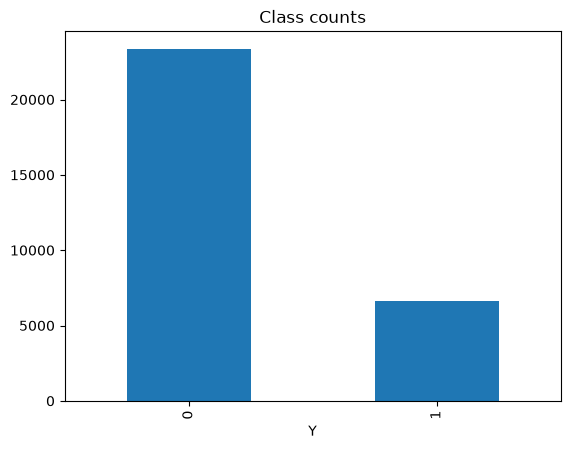

In [66]:
print("missing values:", X_df.isna().sum().sum())

counts = y_df.iloc[:, 0].value_counts()
print(counts)
print(y_df.iloc[:, 0].value_counts(normalize=True).round(3))

counts.plot(kind="bar")
plt.title("Class counts")
plt.show()

In [67]:
from sklearn.model_selection import train_test_split

X_all = X_df.values.astype(np.float64)
y_all = y_df.iloc[:, 0].values.astype(np.float64)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all)

print(X_train.shape, X_test.shape)
print("default rate  train:", y_train.mean().round(4), " test:", y_test.mean().round(4))

(24000, 23) (6000, 23)
default rate  train: 0.2212  test: 0.2212


In [68]:
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
print("smallest std:", sd.min())

Xtr = (X_train - mu) / sd
Xte = (X_test - mu) / sd

smallest std: 0.4889043234622243


In [69]:
Xtr_t = torch.tensor(Xtr, dtype=torch.float64)
Xte_t = torch.tensor(Xte, dtype=torch.float64)
ytr_t = torch.tensor(y_train, dtype=torch.float64)
yte_t = torch.tensor(y_test, dtype=torch.float64)
print(Xtr_t.shape, ytr_t.shape)

torch.Size([24000, 23]) torch.Size([24000])


In [70]:
def sigmoid(z):
    return 1 / (1 + torch.exp(-z))

def cross_entropy(p, y, eps=1e-12):
    p = p.clamp(eps, 1 - eps)          # avoid log(0)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

In [71]:
print(sigmoid(torch.tensor([0.0], dtype=torch.float64)))    # should be 0.5

y_t = torch.tensor([1.0, 1.0, 1.0], dtype=torch.float64)
for p in [0.5, 0.99, 0.01]:
    p_t = torch.tensor([p, p, p], dtype=torch.float64)
    print(p, cross_entropy(p_t, y_t).item())

tensor([0.5000], dtype=torch.float64)
0.5 0.6931471805599453
0.99 0.01005033585350145
0.01 4.605170185988091


In [72]:
p0 = y_train.mean()
baseline_loss = -(p0 * np.log(p0) + (1 - p0) * np.log(1 - p0))
print("baseline cross-entropy:", round(baseline_loss, 4))
print("baseline accuracy (always predict 0):", round(1 - y_test.mean(), 4))

baseline cross-entropy: 0.5284
baseline accuracy (always predict 0): 0.7788


In [73]:
class LogisticRegression:
    """Logistic regression trained with mini-batch SGD on cross-entropy, in PyTorch."""

    def __init__(self, lr=0.1, epochs=30, batch_size=64, seed=0, verbose=True):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed
        self.verbose = verbose
        self.w_ = None               # weights, shape (n_features,)
        self.b_ = None               # bias
        self.loss_history = []       # training cross-entropy after each epoch

    @staticmethod
    def _sigmoid(z):
        return torch.sigmoid(z)

    @staticmethod
    def _cross_entropy(p, y, eps=1e-12):
        p = p.clamp(eps, 1 - eps)
        return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

    def fit(self, X, y):
        X = torch.tensor(np.asarray(X, dtype=np.float64))
        y = torch.tensor(np.asarray(y, dtype=np.float64))
        n, d = X.shape

        w = torch.zeros(d, dtype=X.dtype, requires_grad=True)
        b = torch.zeros(1, dtype=X.dtype, requires_grad=True)
        opt = torch.optim.SGD([w, b], lr=self.lr)

        gen = torch.Generator().manual_seed(self.seed)
        self.loss_history = []

        for epoch in range(self.epochs):
            perm = torch.randperm(n, generator=gen)        # reshuffle every epoch
            for start in range(0, n, self.batch_size):
                idx = perm[start:start + self.batch_size]
                xb, yb = X[idx], y[idx]

                opt.zero_grad()
                p = self._sigmoid(xb @ w + b)
                loss = self._cross_entropy(p, yb)
                loss.backward()
                opt.step()

            with torch.no_grad():                          # full-data loss for a clean curve
                full = self._cross_entropy(self._sigmoid(X @ w + b), y).item()
            self.loss_history.append(full)
            if self.verbose and (epoch % 5 == 0 or epoch == self.epochs - 1):
                print(f"epoch {epoch:3d}  loss {full:.5f}")

        self.w_ = w.detach().numpy()
        self.b_ = b.detach().numpy()
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float64)
        z = X @ self.w_ + self.b_
        return 1 / (1 + np.exp(-z))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [74]:
logit = LogisticRegression(lr=0.1, epochs=30, batch_size=64)
logit.fit(Xtr, y_train)
logit_losses = logit.loss_history

epoch   0  loss 0.46450
epoch   5  loss 0.46377
epoch  10  loss 0.46394
epoch  15  loss 0.46389
epoch  20  loss 0.46356
epoch  25  loss 0.46410
epoch  29  loss 0.46427


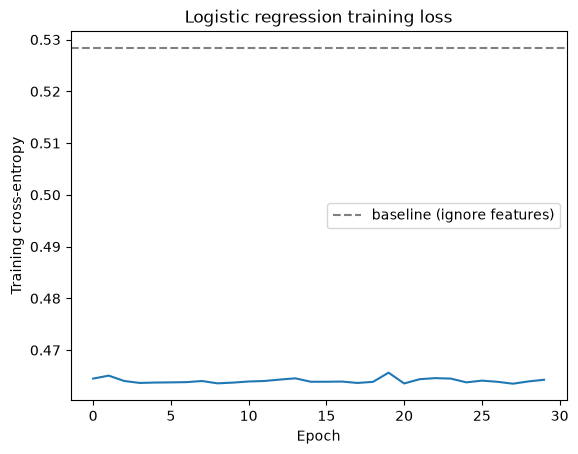

In [75]:
plt.plot(logit_losses)
plt.axhline(baseline_loss, color="gray", linestyle="--", label="baseline (ignore features)")
plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy")
plt.title("Logistic regression training loss")
plt.legend()
plt.show()

In [76]:
from sklearn.linear_model import LogisticRegression as SkLogit
from sklearn.metrics import log_loss

sk = SkLogit(penalty=None, max_iter=1000).fit(Xtr, y_train)

print("my train loss:     ", round(logit_losses[-1], 5))
print("sklearn train loss:", round(log_loss(y_train, sk.predict_proba(Xtr)[:, 1]), 5))

cmp = pd.DataFrame({"mine": logit.w_, "sklearn": sk.coef_[0]},
                   index=[f"X{i+1}" for i in range(Xtr.shape[1])])
cmp["diff"] = cmp["mine"] - cmp["sklearn"]
cmp.round(4)

/home/arwen/hw4/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


my train loss:      0.46427
sklearn train loss: 0.46326


,mine,sklearn,diff
X1,-0.1180,-0.1332,0.0153
X2,0.0128,-0.0560,0.0688
X3,-0.1132,-0.0973,-0.0158
X4,-0.0771,-0.0726,-0.0046
X5,0.1200,0.0739,0.0460
X6,0.6653,0.6613,0.0040
X7,0.1158,0.0929,0.0229
X8,0.1290,0.0973,0.0317
X9,0.0701,0.0603,0.0098
X10,-0.0159,-0.0007,-0.0151


In [77]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score,
                             roc_curve, classification_report)

proba = logit.predict_proba(Xte)
pred = logit.predict(Xte)               # threshold 0.5

print("accuracy: ", round(accuracy_score(y_test, pred), 4))
print("precision:", round(precision_score(y_test, pred), 4))
print("recall:   ", round(recall_score(y_test, pred), 4))
print("F1:       ", round(f1_score(y_test, pred), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, proba), 4))
print("always-predict-0 accuracy:", round(1 - y_test.mean(), 4))
print()
print(classification_report(y_test, pred, target_names=["no default", "default"]))

accuracy:  0.8067
precision: 0.6843
recall:    0.2336
F1:        0.3483
ROC-AUC:   0.7056
always-predict-0 accuracy: 0.7788

              precision    recall  f1-score   support

  no default       0.82      0.97      0.89      4673
     default       0.68      0.23      0.35      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.60      0.62      6000
weighted avg       0.79      0.81      0.77      6000



        pred 0  pred 1
true 0    4530     143
true 1    1017     310


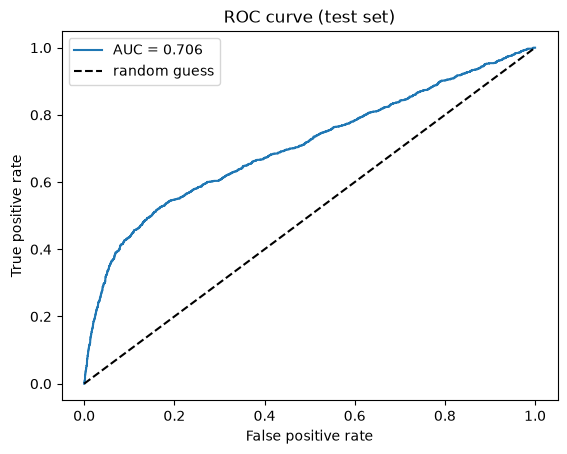

In [78]:
cm = confusion_matrix(y_test, pred)
print(pd.DataFrame(cm, index=["true 0", "true 1"], columns=["pred 0", "pred 1"]))

fpr, tpr, _ = roc_curve(y_test, proba)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (test set)")
plt.legend()
plt.show()

In [79]:
logit_slow = LogisticRegression(lr=0.01, epochs=100, batch_size=64, verbose=False).fit(Xtr, y_train)
print("slow-lr train loss:", round(logit_slow.loss_history[-1], 5))

slow-lr train loss: 0.46332


In [80]:
rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    p = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "accuracy": accuracy_score(y_test, p),
                 "precision": precision_score(y_test, p, zero_division=0),
                 "recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p)})
pd.DataFrame(rows).round(3)

,threshold,accuracy,precision,recall,F1
0,0.10,0.373,0.245,0.884,0.384
1,0.15,0.505,0.277,0.767,0.407
2,0.20,0.637,0.336,0.654,0.444
3,0.25,0.755,0.455,0.537,0.493
4,0.30,0.794,0.540,0.450,0.491
5,0.35,0.807,0.593,0.406,0.482
6,0.40,0.812,0.634,0.361,0.460
7,0.50,0.807,0.684,0.234,0.348


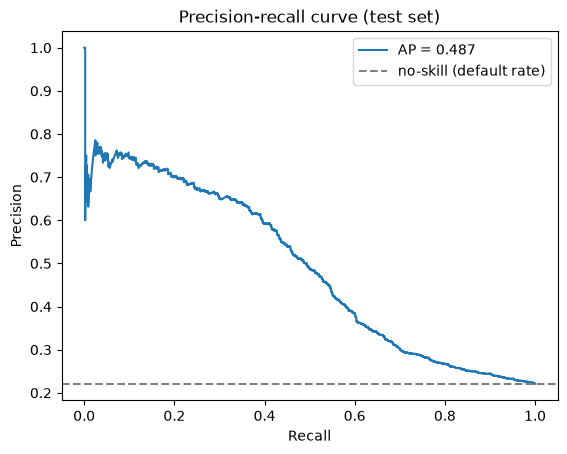

In [81]:
from sklearn.metrics import precision_recall_curve, average_precision_score

prec, rec, _ = precision_recall_curve(y_test, proba)
plt.plot(rec, prec, label=f"AP = {average_precision_score(y_test, proba):.3f}")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="no-skill (default rate)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve (test set)")
plt.legend()
plt.show()

In [82]:
Xsub, Xval, ysub, yval = train_test_split(
    Xtr, y_train, test_size=0.2, random_state=1, stratify=y_train)

logit_v = LogisticRegression(lr=0.1, epochs=30, batch_size=64, verbose=False).fit(Xsub, ysub)
pval = logit_v.predict_proba(Xval)

ths = np.arange(0.10, 0.61, 0.025)
f1s = [f1_score(yval, (pval >= t).astype(int)) for t in ths]
best_t = ths[int(np.argmax(f1s))]
print("best threshold on validation:", round(best_t, 3), " F1:", round(max(f1s), 3))

best threshold on validation: 0.3  F1: 0.511


In [83]:
ptest = logit_v.predict_proba(Xte)
pred_t = (ptest >= best_t).astype(int)

print(classification_report(y_test, pred_t, target_names=["no default", "default"]))
print(pd.DataFrame(confusion_matrix(y_test, pred_t),
                   index=["true 0", "true 1"], columns=["pred 0", "pred 1"]))

              precision    recall  f1-score   support

  no default       0.86      0.90      0.88      4673
     default       0.56      0.46      0.51      1327

    accuracy                           0.80      6000
   macro avg       0.71      0.68      0.69      6000
weighted avg       0.79      0.80      0.79      6000

        pred 0  pred 1
true 0    4195     478
true 1     710     617


In [84]:
def summarize(y_true, p, t):
    pr = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pr).ravel()
    return {"threshold": round(t, 3),
            "accuracy": accuracy_score(y_true, pr),
            "precision": precision_score(y_true, pr),
            "recall": recall_score(y_true, pr),
            "F1": f1_score(y_true, pr),
            "caught (TP)": tp, "missed (FN)": fn,
            "false alarms (FP)": fp, "correct rejects (TN)": tn}

pd.DataFrame([summarize(y_test, ptest, 0.5), summarize(y_test, ptest, best_t)],
             index=["default cutoff", "validation-tuned cutoff"]).round(3)

,threshold,accuracy,precision,recall,F1,caught (TP),missed (FN),false alarms (FP),correct rejects (TN)
default cutoff,0.5,0.812,0.662,0.301,0.414,400,927,204,4469
validation-tuned cutoff,0.3,0.802,0.563,0.465,0.509,617,710,478,4195


In [85]:
print("ROC-AUC (logit_v):", round(roc_auc_score(y_test, ptest), 4))
print("AP (logit_v):     ", round(average_precision_score(y_test, ptest), 4))

ROC-AUC (logit_v): 0.7022
AP (logit_v):      0.494


In [86]:
pred_full = (proba >= best_t).astype(int)
print(classification_report(y_test, pred_full, target_names=["no default", "default"]))

              precision    recall  f1-score   support

  no default       0.85      0.89      0.87      4673
     default       0.54      0.45      0.49      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.67      0.68      6000
weighted avg       0.78      0.79      0.79      6000

